In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px

%matplotlib inline

print("All libraries imported successfully!")

All libraries imported successfully!


In [23]:
df = pd.read_csv("../Task_1_Data_Cleaning/output/Netflix_Cleaned.csv")

print("Netflix Business Analysis Dataset Loaded!")
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])

df.head()

Netflix Business Analysis Dataset Loaded!
Total Records: 8790
Total Columns: 10


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [24]:
print("========== DATASET INFORMATION ==========")

print("\nDataset Information:")
df.info()

print("\n========== DATA QUALITY CHECK ==========")

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\n========== STATISTICAL SUMMARY ==========")

display(df.describe(include="all"))

========== DATASET INFORMATION ==========

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB

========== DATA QUALITY CHECK ==========

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate Records:
0

========== STATISTICAL SU

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
count,8790,8790,8790,8790,8790,8790,8790.000000,8790,8790,8790
unique,8790,2,8786,4528,86,1713,NaN,14,220,513
top,s1,Movie,9-Feb,Not Given,United States,1/1/2020,NaN,TV-MA,1 Season,"Dramas, International Movies"
freq,1,6126,2,2588,3240,110,NaN,3205,1791,362
mean,NaN,NaN,NaN,NaN,NaN,NaN,2014.183163,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,8.825466,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN


In [25]:
# Total Content
total_content = len(df)

# Movies and TV Shows
total_movies = (df["type"] == "Movie").sum()
total_tv_shows = (df["type"] == "TV Show").sum()

# Content Percentages
movie_percentage = (total_movies / total_content) * 100
tv_percentage = (total_tv_shows / total_content) * 100

# Most Common Rating
most_common_rating = df["rating"].mode()[0]

# Top Country (excluding Unknown)
top_country = (
    df[df["country"] != "Unknown"]["country"]
    .value_counts()
    .idxmax()
)

# Calculate Most Common Genre
genre_data = df["listed_in"].str.split(",").explode().str.strip()
top_genre = genre_data.value_counts().idxmax()

# Display Business KPIs
print("========== NETFLIX BUSINESS KPIs ==========")

print("\nTotal Content:", total_content)

print("\nTotal Movies:", total_movies)
print("Total TV Shows:", total_tv_shows)

print("\nMovie Percentage:", round(movie_percentage, 2), "%")
print("TV Show Percentage:", round(tv_percentage, 2), "%")

print("\nMost Common Rating:", most_common_rating)
print("Top Content Producing Country:", top_country)
print("Most Common Genre:", top_genre)

========== NETFLIX BUSINESS KPIs ==========

Total Content: 8790

Total Movies: 6126
Total TV Shows: 2664

Movie Percentage: 69.69 %
TV Show Percentage: 30.31 %

Most Common Rating: TV-MA
Top Content Producing Country: United States
Most Common Genre: International Movies


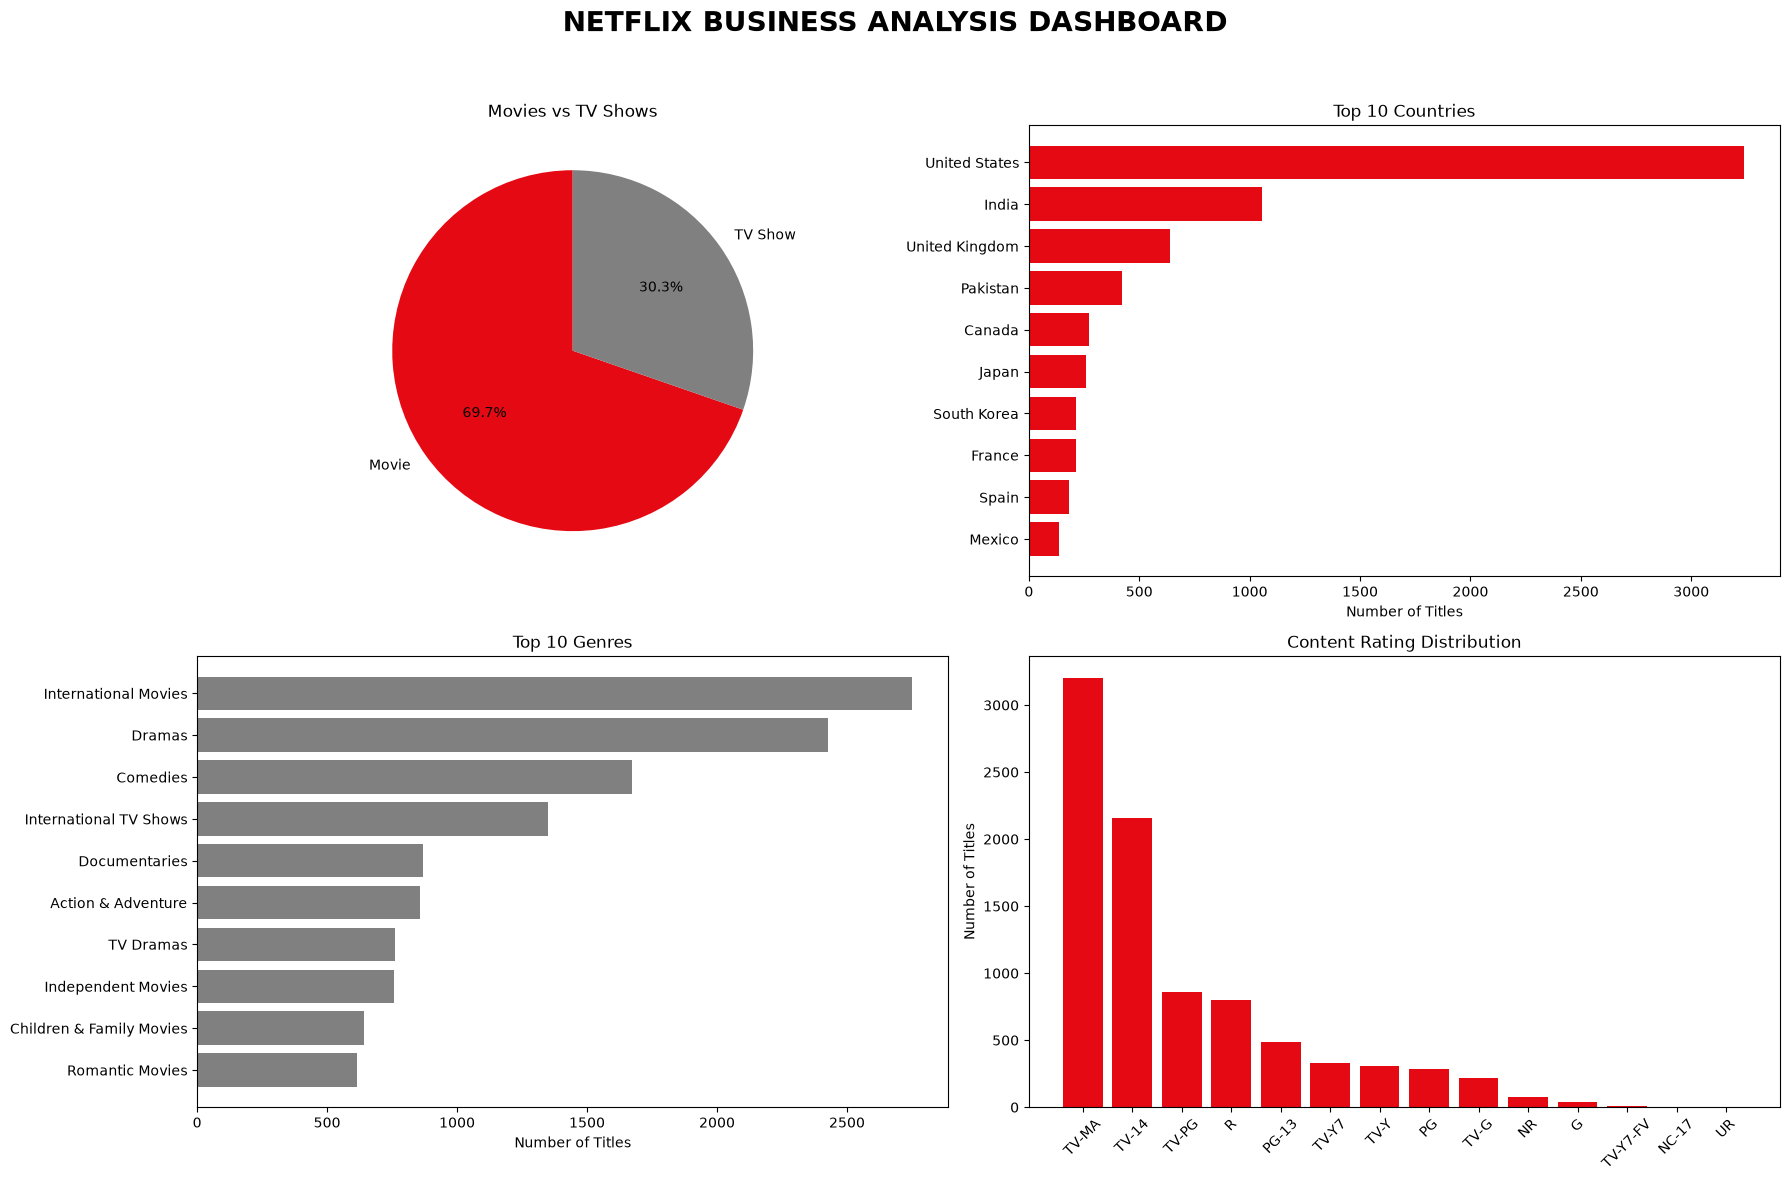

In [26]:
# Prepare dashboard data

content_type_counts = df["type"].value_counts()

country_counts = (
    df[df["country"] != "Unknown"]["country"]
    .value_counts()
    .head(10)
)

genre_counts_dashboard = (
    df["listed_in"]
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

rating_counts_dashboard = df["rating"].value_counts()


# Create Dashboard

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

fig.suptitle(
    "NETFLIX BUSINESS ANALYSIS DASHBOARD",
    fontsize=20,
    fontweight="bold"
)


# 1. Content Type Distribution

axes[0, 0].pie(
    content_type_counts.values,
    labels=content_type_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E50914", "grey"]
)

axes[0, 0].set_title("Movies vs TV Shows")


# 2. Top 10 Countries

axes[0, 1].barh(
    country_counts.index[::-1],
    country_counts.values[::-1],
    color="#E50914"
)

axes[0, 1].set_title("Top 10 Countries")
axes[0, 1].set_xlabel("Number of Titles")


# 3. Top 10 Genres

axes[1, 0].barh(
    genre_counts_dashboard.index[::-1],
    genre_counts_dashboard.values[::-1],
    color="grey"
)

axes[1, 0].set_title("Top 10 Genres")
axes[1, 0].set_xlabel("Number of Titles")


# 4. Rating Distribution

axes[1, 1].bar(
    rating_counts_dashboard.index,
    rating_counts_dashboard.values,
    color="#E50914"
)

axes[1, 1].set_title("Content Rating Distribution")
axes[1, 1].set_ylabel("Number of Titles")
axes[1, 1].tick_params(axis="x", rotation=45)


plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Key Business Insights & Recommendations

### 1. Content Type Distribution
Movies account for 69.69% of the Netflix content library, while TV Shows represent 30.31%.

**Recommendation:** Maintain a strong movie library while exploring opportunities to expand TV Show content.

### 2. Country-Wise Content Distribution
The United States contributes the largest number of titles, followed by India and the United Kingdom.

**Recommendation:** Continue strengthening regional content while exploring opportunities in underrepresented markets.

### 3. Genre Preferences
International Movies, Dramas and Comedies are the three most common genres.

**Recommendation:** Continue evaluating these popular genres while maintaining variety across other categories.

### 4. Content Ratings
TV-MA is the most common rating, followed by TV-14.

**Recommendation:** Maintain a diverse content catalogue for different audience age groups.

### 5. Content Library Strategy
The dataset contains 8,790 titles across 86 country entries and 42 distinct genre categories.

**Recommendation:** Use these patterns to support content planning, regional diversification and catalogue management.

### Overall Business Recommendation
Netflix can use content distribution, genre popularity, country representation and rating patterns to make informed catalogue-planning decisions. These findings describe the available dataset and should be combined with viewership and engagement data before making actual investment decisions.

# Netflix Data Analysis – Final Business Report

## 1. Project Overview

This project focuses on analyzing Netflix's content dataset using Python. The objective is to understand content distribution, country-wise availability, release-year trends, content ratings and genre patterns.

## 2. Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Jupyter Notebook

## 3. Dataset Summary

- Total Records: 8,790
- Total Columns: 10
- Unique Countries: 86
- Unique Ratings: 14
- Release Year Range: 1925–2021
- Missing Values: 0
- Duplicate Records: 0

## 4. Major Findings

- Movies represent 69.69% of the content library.
- TV Shows represent 30.31%.
- The United States is the leading country by content count.
- International Movies is the most common genre.
- TV-MA is the most common content rating.
- 2018 recorded the highest number of titles by release year, with 1,146 titles.

## 5. Business Insights

The analysis shows that Netflix's catalogue contains a larger proportion of Movies than TV Shows. International Movies, Dramas and Comedies are the leading genres. Mature-audience ratings, particularly TV-MA and TV-14, have the highest representation.

The country-wise and release-year analysis also highlights the concentration of titles across particular markets and recent release periods.

## 6. Recommendations

1. Maintain a balanced content library across Movies and TV Shows.
2. Explore opportunities to strengthen regional content representation.
3. Continue monitoring popular genres while maintaining content diversity.
4. Maintain content suitable for different audience age groups.
5. Use viewership and engagement data alongside catalogue analysis for future content decisions.

## 7. Conclusion

This project demonstrates how Python-based data analysis can help understand a large content library and identify meaningful patterns.

Through data cleaning, exploratory analysis, visualization and business interpretation, the project provides a structured overview of Netflix's content distribution and potential business opportunities.

**Project Status:** All six internship tasks completed.